# Proyecto Final: Pipeline Integral de Limpieza y Análisis Exploratorio de Datos (EDA)

**Tema:** Ventas y satisfacción en el marketplace brasileño Olist (2016-2018)

## Datos académicos

- **Materia:** Ciencia de Datos
- **Docente:** Fernando Mayorga Guittins
- **Fecha:** octubre de 2026
- **Integrantes del equipo:**
  - Arturo Obed Velázquez Téllez
  - Ángel de Jesús González Molina
  - Antonia Martínez Santos
  - José Carlos Hernández Ballado

## Contexto de los datos

- **Fuente:** *Brazilian E-Commerce Public Dataset by Olist* (Kaggle, `olistbr/brazilian-ecommerce`).
- **Qué representa:** pedidos reales hechos entre 2016 y 2018 en tiendas que venden a través de Olist (Brasil).
- **Archivo principal:** pedidos (`orders`) + productos vendidos (`items`) = **112,650 filas y 14 columnas**
  (numéricas, categóricas y fechas).
- **Archivos secundarios (para el merge):** productos, clientes y reseñas.

## Objetivos del análisis

1. **¿Qué categorías de producto generan más ingreso?**
2. **¿El retraso en la entrega baja la calificación que da el cliente?**
3. **¿Cómo varían las ventas por mes y por estado?**

## 2. Importación de librerías y configuración

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Si pandas lanza un SettingWithCopyWarning, se vuelve error y el notebook se detiene.
# (En pandas 3 esa advertencia ya no existe; el "if" evita fallar en esa versión.)
if hasattr(pd.errors, "SettingWithCopyWarning"):
    warnings.simplefilter("error", pd.errors.SettingWithCopyWarning)

pd.set_option("display.max_columns", None)               # mostrar todas las columnas
pd.set_option("display.float_format", "{:,.2f}".format)  # números con 2 decimales y comas

DATA_DIR = Path("data")  # carpeta donde están los CSV

## 3. Carga e inspección inicial de los datos

- **Principal:** `orders` (pedidos) + `items` (productos de cada pedido), unidos por `order_id`.
  Un pedido puede tener varios productos, así que cada fila de `ventas` es **un producto vendido**.
- **Secundarios:** `products`, `customers` y `reviews`. Se limpian en la sección 4 y se unen en la 5.

In [2]:
# Se cargan los archivos tal como vienen, sin modificarlos
orders = pd.read_csv(DATA_DIR / "olist_orders_dataset.csv")
items = pd.read_csv(DATA_DIR / "olist_order_items_dataset.csv")
products = pd.read_csv(DATA_DIR / "olist_products_dataset.csv")
customers = pd.read_csv(DATA_DIR / "olist_customers_dataset.csv")
reviews = pd.read_csv(DATA_DIR / "olist_order_reviews_dataset.csv")

# Tabla principal: pedidos + productos vendidos
ventas = orders.merge(items, on="order_id", how="inner")
print(f"ventas: {ventas.shape[0]:,} filas x {ventas.shape[1]} columnas")

ventas: 112,650 filas x 14 columnas


In [3]:
ventas.head()  # primeras 5 filas

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00,1,87285b34884572647811a353c7ac498a,3504c0cb71d7fa48d967e0e4c94d59d9,2017-10-06 11:07:15,29.99,8.72
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00,1,595fac2a385ac33a80bd5114aec74eb8,289cdb325fb7e7f891c38608bf9e0962,2018-07-30 03:24:27,118.70,22.76
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00,1,aa4383b373c6aca5d8797843e5594415,4869f7a5dfa277a7dca6462dcf3b52b2,2018-08-13 08:55:23,159.90,19.22
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00,1,d0b61bfb1de832b15ba9d266ca96e5b0,66922902710d126a0e7d26b0e3805106,2017-11-23 19:45:59,45.00,27.20
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00,1,65266b2da20d04dbe00c5c2d3bb7859e,2c9e548be18521d1c43cde1c582c6de8,2018-02-19 20:31:37,19.90,8.72


In [4]:
ventas.info()  # tipos de dato y valores no nulos por columna

<class 'pandas.DataFrame'>
RangeIndex: 112650 entries, 0 to 112649
Data columns (total 14 columns):
 #   Column                         Non-Null Count   Dtype  
---  ------                         --------------   -----  
 0   order_id                       112650 non-null  str    
 1   customer_id                    112650 non-null  str    
 2   order_status                   112650 non-null  str    
 3   order_purchase_timestamp       112650 non-null  str    
 4   order_approved_at              112635 non-null  str    
 5   order_delivered_carrier_date   111456 non-null  str    
 6   order_delivered_customer_date  110196 non-null  str    
 7   order_estimated_delivery_date  112650 non-null  str    
 8   order_item_id                  112650 non-null  int64  
 9   product_id                     112650 non-null  str    
 10  seller_id                      112650 non-null  str    
 11  shipping_limit_date            112650 non-null  str    
 12  price                          112650 non

In [5]:
ventas.describe()  # estadísticas de las columnas numéricas

,order_item_id,price,freight_value
count,"112,650.00","112,650.00","112,650.00"
mean,1.20,120.65,19.99
std,0.71,183.63,15.81
min,1.00,0.85,0.00
25%,1.00,39.90,13.08
50%,1.00,74.99,16.26
75%,1.00,134.90,21.15
max,21.00,"6,735.00",409.68


## 4. Limpieza y preprocesamiento

### 4.1 Tratamiento de valores nulos

In [6]:
# Cuántos nulos hay por columna en la tabla principal
nulos = ventas.isna().sum()
nulos[nulos > 0]

order_approved_at                  15
order_delivered_carrier_date     1194
order_delivered_customer_date    2454
dtype: int64

**Decisiones (una por tipo de nulo):**

1. **Pedido `delivered` sin fecha de entrega → se elimina.** Es un registro inconsistente y no sirve para
   medir retrasos. Son muy pocas filas.
2. **Fecha de aprobación vacía → se imputa con la mediana.** Se calcula cuánto tarda normalmente un pedido en
   aprobarse y se suma a la fecha de compra. Se usa la **mediana** y no la media porque unos pocos pedidos
   tardaron muchísimo y subirían el promedio.
3. **Fecha de entrega vacía en pedidos no entregados → se deja vacía.** Un pedido cancelado o en camino
   todavía no tiene fecha de entrega; inventarla sería falso.
4. **Productos:** categoría vacía → `sin_categoria`; medidas vacías (peso, tamaño) → mediana.

In [7]:
# 1) Pedidos "delivered" sin fecha de entrega -> se eliminan
sin_fecha = (ventas["order_status"] == "delivered") & ventas["order_delivered_customer_date"].isna()
ventas = ventas.loc[~sin_fecha].copy()
print(f"Filas eliminadas: {sin_fecha.sum()}")

# 2) Fecha de aprobación vacía -> fecha de compra + mediana del tiempo de aprobación
compra = pd.to_datetime(ventas["order_purchase_timestamp"])
aprobado = pd.to_datetime(ventas["order_approved_at"])
mediana = (aprobado - compra).median()
ventas["order_approved_at"] = aprobado.fillna(compra + mediana)
print(f"Mediana del tiempo de aprobación: {mediana}")

# 3) Fechas de entrega de pedidos no entregados: se dejan vacías a propósito

# 4) Productos: categoría vacía -> "sin_categoria"; columnas numéricas vacías -> mediana
products["product_category_name"] = products["product_category_name"].fillna("sin_categoria")
numericas = products.select_dtypes("number").columns
products[numericas] = products[numericas].fillna(products[numericas].median())
print(f"Nulos que quedan en products: {products.isna().sum().sum()}")

Filas eliminadas: 8
Mediana del tiempo de aprobación: 0 days 00:21:02
Nulos que quedan en products: 0


### 4.2 Manejo de duplicados

En `reviews` hay pedidos con **más de una reseña**. Si se dejan, al unir las tablas cada venta se repetiría
y el ingreso saldría inflado. Se conserva **la reseña más reciente** de cada pedido.

In [8]:
# Filas idénticas en la tabla principal
print("Filas duplicadas en ventas:", ventas.duplicated().sum())

# Pedidos con más de una reseña
print("Pedidos con reseña repetida:", reviews.duplicated(subset="order_id").sum())

# Ordenar por fecha de respuesta y quedarse con la última reseña de cada pedido
reviews = reviews.sort_values("review_answer_timestamp").drop_duplicates(subset="order_id", keep="last")
print("Pedidos con reseña repetida después:", reviews.duplicated(subset="order_id").sum())

Filas duplicadas en ventas: 0
Pedidos con reseña repetida: 559
Pedidos con reseña repetida después: 0


### 4.3 Corrección de tipos de datos (casteo)

Las fechas llegaron como **texto**. Se convierten a `datetime` para poder restarlas (calcular retrasos)
y agruparlas por mes.

In [9]:
columnas_fecha = [
    "order_purchase_timestamp",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date",
    "shipping_limit_date",
]
for columna in columnas_fecha:
    ventas[columna] = pd.to_datetime(ventas[columna])  # texto -> fecha

ventas.dtypes  # comprobar que ahora son datetime64

order_id                                    str
customer_id                                 str
order_status                                str
order_purchase_timestamp         datetime64[us]
order_approved_at                datetime64[us]
order_delivered_carrier_date     datetime64[us]
order_delivered_customer_date    datetime64[us]
order_estimated_delivery_date    datetime64[us]
order_item_id                             int64
product_id                                  str
seller_id                                   str
shipping_limit_date              datetime64[us]
price                                   float64
freight_value                           float64
dtype: object

### 4.4 Estandarización de texto

Se quitan espacios sobrantes y se unifican mayúsculas/minúsculas, para que `"SP "`, `"sp"` y `"Sp"`
cuenten como el mismo valor. Los estados van en mayúsculas porque son siglas (`SP`, `RJ`).

In [10]:
ventas["order_status"] = ventas["order_status"].str.strip().str.lower()
products["product_category_name"] = products["product_category_name"].str.strip().str.lower()
customers["customer_city"] = customers["customer_city"].str.strip().str.lower()
customers["customer_state"] = customers["customer_state"].str.strip().str.upper()

print("Estatus de pedido:", sorted(ventas["order_status"].unique()))
print("Estados:", sorted(customers["customer_state"].unique()))

Estatus de pedido: ['approved', 'canceled', 'delivered', 'invoiced', 'processing', 'shipped', 'unavailable']
Estados: ['AC', 'AL', 'AM', 'AP', 'BA', 'CE', 'DF', 'ES', 'GO', 'MA', 'MG', 'MS', 'MT', 'PA', 'PB', 'PE', 'PI', 'PR', 'RJ', 'RN', 'RO', 'RR', 'RS', 'SC', 'SE', 'SP', 'TO']


## 5. Enriquecimiento e ingeniería de características

### 5.1 Cruce de datos (merge)

A cada venta se le agregan datos de las tablas secundarias con `how="left"` (se conservan todas las ventas):

| Tabla | Se une por | Aporta |
|---|---|---|
| `products` | `product_id` | categoría del producto |
| `customers` | `customer_id` | estado del cliente |
| `reviews` | `order_id` | calificación (1 a 5) |

`validate="m:1"` hace que pandas marque error si la llave se repite en la tabla secundaria
(evita duplicar ventas por accidente).

In [11]:
df = (
    ventas
    .merge(products[["product_id", "product_category_name"]], on="product_id", how="left", validate="m:1")
    .merge(customers[["customer_id", "customer_state"]], on="customer_id", how="left", validate="m:1")
    .merge(reviews[["order_id", "review_score"]], on="order_id", how="left", validate="m:1")
)
df = df.rename(columns={"product_category_name": "categoria", "customer_state": "estado"})

assert len(df) == len(ventas), "El merge agregó filas"  # comprobación
print(f"df: {df.shape[0]:,} filas x {df.shape[1]} columnas")

df: 112,642 filas x 17 columnas


### 5.2 Nuevas columnas con operaciones vectorizadas (numpy)

Todas se calculan sobre la columna completa a la vez, **sin ciclos `for`**:

- `ingreso` = precio + flete.
- `anio_mes` = mes de la compra (para agrupar).
- `retraso_dias` = días completos entre la entrega real y la estimada (positivo = llegó tarde).
- `estatus_entrega` con **`np.select`** (varias condiciones): `no_entregado`, `tardia` o `a_tiempo`.
- `envio_caro` con **`np.where`** (una condición): `si` cuando el flete cuesta más que el producto.

In [12]:
df["ingreso"] = df["price"] + df["freight_value"]
df["anio_mes"] = df["order_purchase_timestamp"].dt.to_period("M").astype(str)
df["retraso_dias"] = (df["order_delivered_customer_date"] - df["order_estimated_delivery_date"]).dt.days

# np.select: revisa las condiciones en orden y asigna la etiqueta de la primera que se cumple
df["estatus_entrega"] = np.select(
    [df["order_delivered_customer_date"].isna(), df["retraso_dias"] > 0],
    ["no_entregado", "tardia"],
    default="a_tiempo",
)

# np.where: si la condición es verdadera -> "si", si no -> "no"
df["envio_caro"] = np.where(df["freight_value"] > df["price"], "si", "no")

print(df["estatus_entrega"].value_counts(), "\n")
print(df["envio_caro"].value_counts())

estatus_entrega
a_tiempo        102931
tardia            7265
no_entregado      2446
Name: count, dtype: int64 

envio_caro
no    108518
si      4124
Name: count, dtype: int64


### 5.3 Tratamiento de outliers (Z-score con numpy)

El **Z-score** mide a cuántas desviaciones estándar está un valor del promedio:
`z = (x - media) / desviación`. Se considera atípico si `|z| > 3`.

In [13]:
precio = df["price"].to_numpy()
z = (precio - np.mean(precio)) / np.std(precio)
df["outlier_precio"] = np.abs(z) > 3

print(f"Outliers de precio: {df['outlier_precio'].sum():,} ({df['outlier_precio'].mean():.2%} de las ventas)")
print(f"Precio máximo: {precio.max():,.2f} | precio mediano: {np.median(precio):,.2f}")

Outliers de precio: 1,966 (1.75% de las ventas)
Precio máximo: 6,735.00 | precio mediano: 74.99


**Decisión: los outliers se marcan pero NO se eliminan.** Un precio alto es un producto caro **real**, no un
error de captura. Borrarlo quitaría ingreso que sí se cobró y cambiaría la respuesta de la pregunta 1.
La columna `outlier_precio` permite filtrarlos si algún análisis lo necesita.

## 6. Análisis Exploratorio de Datos (EDA) y respuestas

Para ingresos solo se toman ventas **válidas**: se excluyen pedidos `canceled` y `unavailable` (no se cobraron).

In [14]:
validas = df.loc[~df["order_status"].isin(["canceled", "unavailable"])].copy()
print(f"Ventas válidas: {len(validas):,} de {len(df):,}")

Ventas válidas: 112,093 de 112,642


### Pregunta 1: ¿Qué categorías de producto generan más ingreso?

Las 10 primeras suman 62.33% del ingreso


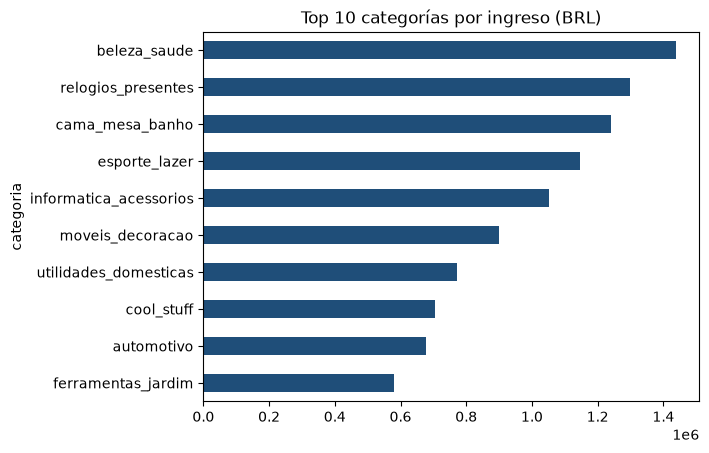

,ingreso_total,pedidos,participacion_%
categoria,,,
beleza_saude,"1,437,665.78",8800,9.14
relogios_presentes,"1,297,976.33",5602,8.25
cama_mesa_banho,"1,240,386.13",9399,7.88
esporte_lazer,"1,147,050.63",7672,7.29
informatica_acessorios,"1,050,821.46",6653,6.68
moveis_decoracao,"899,626.04",6425,5.72
utilidades_domesticas,"772,035.14",5847,4.91
cool_stuff,"704,086.24",3616,4.47
automotivo,"678,471.81",3871,4.31


In [15]:
por_categoria = (
    validas.groupby("categoria")
    .agg(ingreso_total=("ingreso", "sum"), pedidos=("order_id", "nunique"))
    .sort_values("ingreso_total", ascending=False)
)
por_categoria["participacion_%"] = por_categoria["ingreso_total"] / por_categoria["ingreso_total"].sum() * 100

top10 = por_categoria.head(10)
print(f"Las 10 primeras suman {top10['participacion_%'].sum():.2f}% del ingreso")

top10["ingreso_total"].sort_values().plot.barh(title="Top 10 categorías por ingreso (BRL)", color="#1F4E79")
plt.show()
top10

**Interpretación:** **beleza_saude** (belleza y salud) es la categoría que más vende: 1,437,665.78 BRL, el 9.14 % del ingreso. Le siguen **relogios_presentes** (relojes y regalos, 8.25 %) y **cama_mesa_banho** (cama, mesa y baño, 7.88 %). Las 10 primeras categorías juntan el **62.33 %** del ingreso, así que pocas líneas de producto concentran la mayor parte de las ventas. No todas ganan igual: relojes y regalos vende casi lo mismo que cama, mesa y baño con muchos menos pedidos (5,602 contra 9,399), porque sus productos son más caros.